# Parameter Sweep: Wild Count

Before automating the search over reel composition (Phase 6), a single lever can be swept by hand to see how the outputs respond. This notebook varies the Wild count and plots two things separately:

1. **Raw RTP** as the Wild count increases, without correction. This is expected to rise sharply, since Wild both substitutes for other symbols and pays on its own.
2. **Hit frequency and coefficient of variation (CV)**, the quantities unaffected by the Phase 6 RTP rescaling, which are what an optimizer actually searches over once RTP is corrected.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    while not (current / "engine").is_dir():
        if current.parent == current:
            raise RuntimeError("could not locate repo root (no engine/ found)")
        current = current.parent
    return current


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))

%matplotlib inline
import random

import matplotlib.pyplot as plt

from analytics.optimizer import build_machine_from_composition
from analytics.statistics import compute_statistics
from engine.config import load_template_paytable
from engine.symbols import Symbol
from simulation.simulate import run_spins

## Running the sweep

The Wild count runs from 0 to 6, and the Cherry count is reduced by the same amount to keep each reel at 20 stops. Only the balance between Wild and Cherry changes, so the comparison is like for like.

In [2]:
paylines, template_paytable, template_scatter_paytable = load_template_paytable(
    str(REPO_ROOT / "configs" / "default_game.json")
)

BASE_COMPOSITION = {
    Symbol.CHERRY: 5,
    Symbol.LEMON: 4,
    Symbol.ORANGE: 3,
    Symbol.PLUM: 3,
    Symbol.BAR: 2,
    Symbol.SEVEN: 1,
    Symbol.WILD: 1,
    Symbol.SCATTER: 1,
}
NUM_SPINS = 100_000

wild_counts = list(range(0, 7))
raw_rtps = []
hit_freqs = []
cvs = []

for wild_count in wild_counts:
    cherry_count = BASE_COMPOSITION[Symbol.CHERRY] + BASE_COMPOSITION[Symbol.WILD] - wild_count
    composition = dict(BASE_COMPOSITION)
    composition[Symbol.WILD] = wild_count
    composition[Symbol.CHERRY] = cherry_count

    machine = build_machine_from_composition(
        composition, template_paytable, template_scatter_paytable, paylines, num_reels=5, num_rows=3
    )
    batch = run_spins(machine, NUM_SPINS, bet=1.0, rng=random.Random(100 + wild_count))
    stats = compute_statistics(batch)

    raw_rtps.append(stats.rtp)
    hit_freqs.append(stats.hit_frequency)
    cvs.append(stats.coefficient_of_variation)

    print(
        f"wild={wild_count} cherry={cherry_count}: raw_rtp={stats.rtp:.2%} "
        f"hit_freq={stats.hit_frequency:.2%} cv={stats.coefficient_of_variation:.2f}"
    )

wild=0 cherry=6: raw_rtp=57.08% hit_freq=12.37% cv=3.87


wild=1 cherry=5: raw_rtp=98.30% hit_freq=20.83% cv=3.00


wild=2 cherry=4: raw_rtp=176.89% hit_freq=27.64% cv=2.90


wild=3 cherry=3: raw_rtp=305.72% hit_freq=34.15% cv=3.06


wild=4 cherry=2: raw_rtp=490.84% hit_freq=41.44% cv=2.93


wild=5 cherry=1: raw_rtp=796.71% hit_freq=49.32% cv=2.92


wild=6 cherry=0: raw_rtp=1214.97% hit_freq=56.30% cv=2.80


## Raw RTP rises sharply with Wild count (uncorrected)

As in Phases 2 and 5, changing reel composition without correcting the paytable quickly produces an unusable RTP.

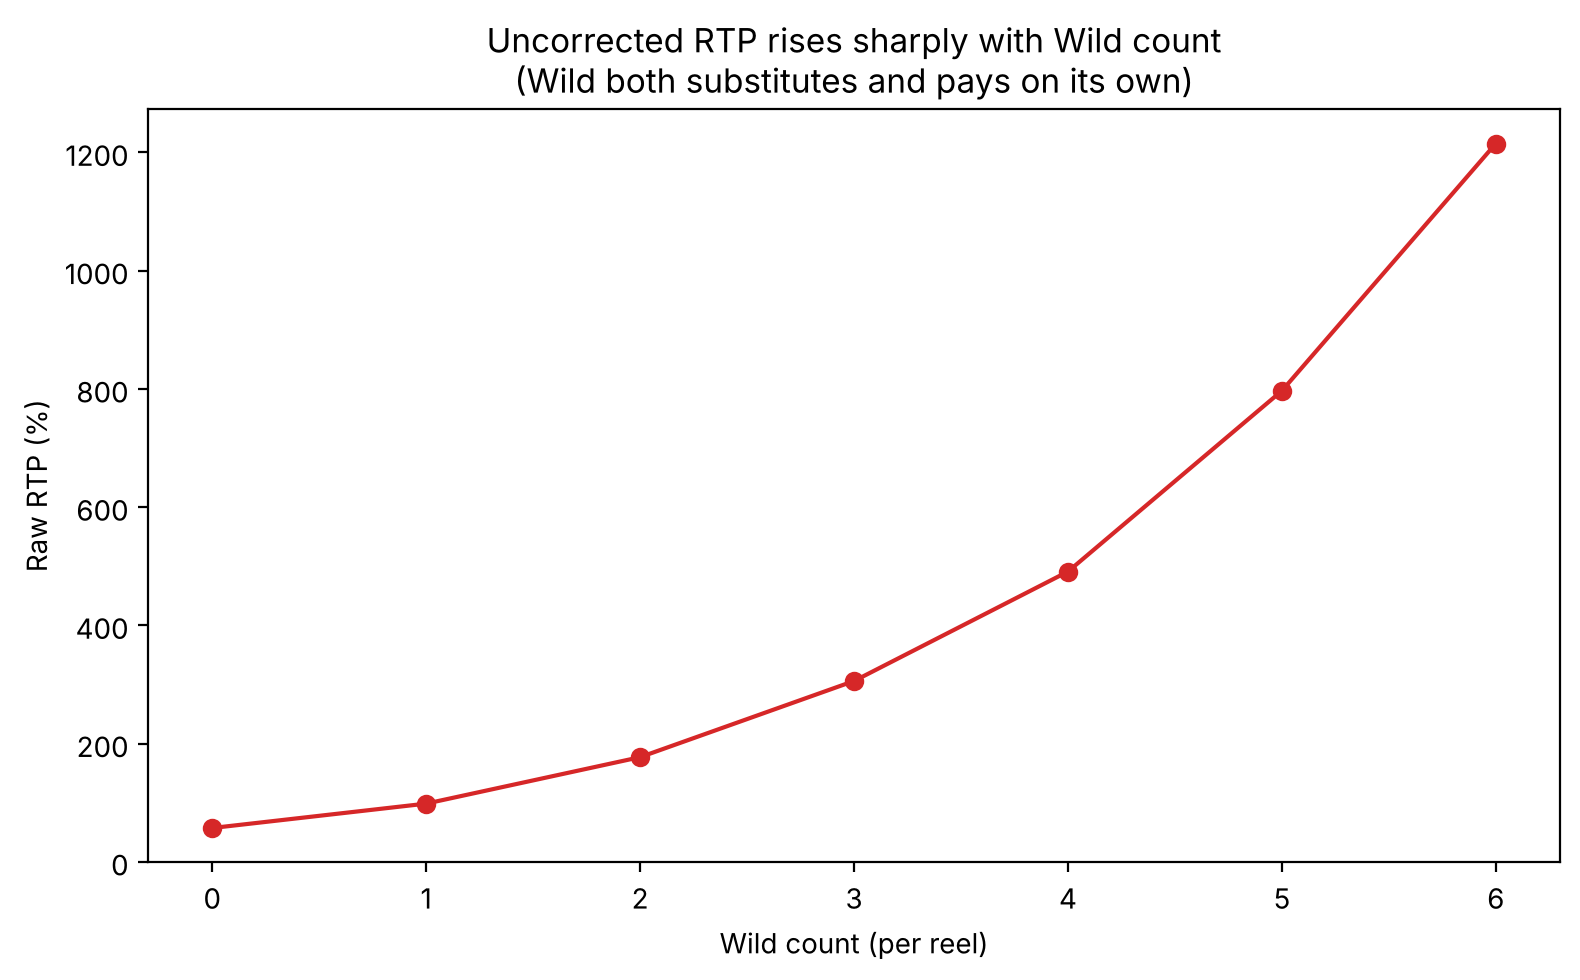

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(wild_counts, [r * 100 for r in raw_rtps], marker="o", color="#d62728")
ax.set_xlabel("Wild count (per reel)")
ax.set_ylabel("Raw RTP (%)")
ax.set_title("Uncorrected RTP rises sharply with Wild count\n(Wild both substitutes and pays on its own)")
plt.tight_layout()
plt.show()

## Hit frequency and volatility after RTP correction

As shown in Phase 6, rescaling every payout by a constant to reach a target RTP leaves hit frequency and CV unchanged. These two curves, rather than the RTP curve above, form the search space that `optimize_composition()` explores: composition determines the shape of the distribution, and payout scale independently determines RTP.

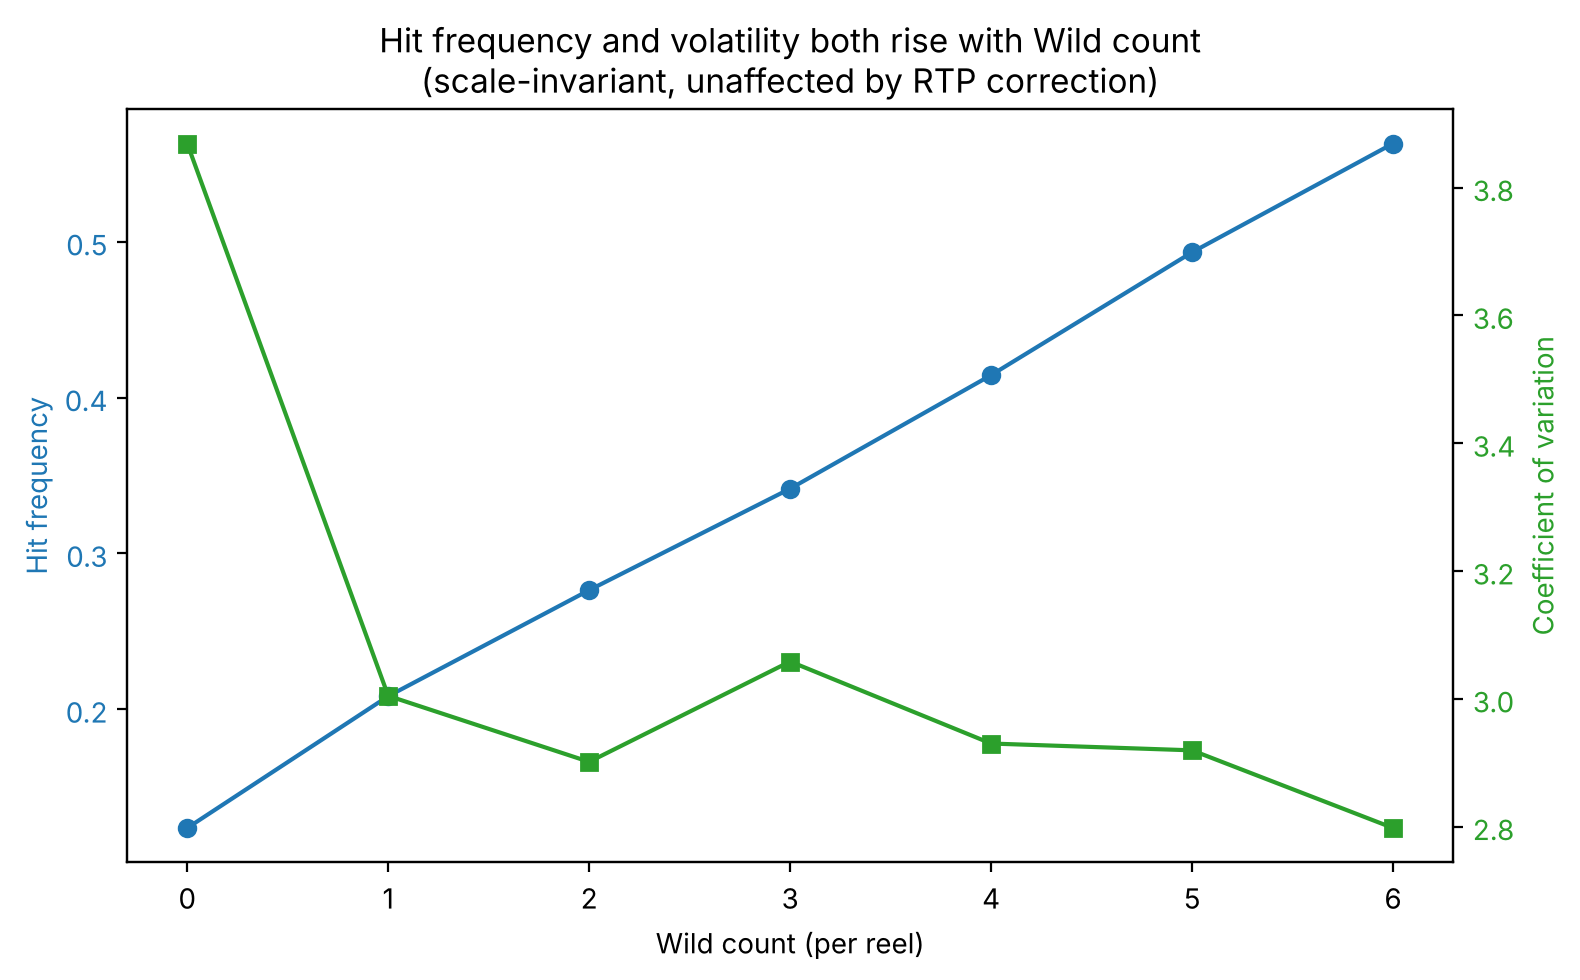

In [4]:
fig, ax1 = plt.subplots(figsize=(8, 5))

color1 = "#1f77b4"
ax1.set_xlabel("Wild count (per reel)")
ax1.set_ylabel("Hit frequency", color=color1)
ax1.plot(wild_counts, hit_freqs, marker="o", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)

ax2 = ax1.twinx()
color2 = "#2ca02c"
ax2.set_ylabel("Coefficient of variation", color=color2)
ax2.plot(wild_counts, cvs, marker="s", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)

plt.title("Hit frequency and volatility both rise with Wild count\n(scale-invariant, unaffected by RTP correction)")
plt.tight_layout()
plt.show()

## Takeaway

This sweep is a one-dimensional, manual version of the hill-climbing search in `analytics/optimizer.py`, which works across all 8 symbols at once. It explores composition, which moves hit frequency and volatility, and solves payout scale separately, which moves RTP. Seeing the single-variable case plotted makes the automated search in Phase 6 easier to interpret.